In [202]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from lazypredict.Supervised import LazyRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import LabelEncoder
import joblib

In [203]:
df=pd.read_csv("../MachineLearningAgain/MachineLearningDataSets/laptopPrice_data.csv")
df.head()

,brand,processor_brand,processor_name,processor_gnrtn,ram_gb,ram_type,ssd,hdd,os,os_bit,graphic_card_gb,weight,warranty,Touchscreen,msoffice,Price,rating,Number of Ratings,Number of Reviews
0,ASUS,Intel,Core i3,10th,4 GB,DDR4,0 GB,1024 GB,Windows,64-bit,0 GB,Casual,No warranty,No,No,34649,2 stars,3,0
1,Lenovo,Intel,Core i3,10th,4 GB,DDR4,0 GB,1024 GB,Windows,64-bit,0 GB,Casual,No warranty,No,No,38999,3 stars,65,5
2,Lenovo,Intel,Core i3,10th,4 GB,DDR4,0 GB,1024 GB,Windows,64-bit,0 GB,Casual,No warranty,No,No,39999,3 stars,8,1
3,ASUS,Intel,Core i5,10th,8 GB,DDR4,512 GB,0 GB,Windows,32-bit,2 GB,Casual,No warranty,No,No,69990,3 stars,0,0
4,ASUS,Intel,Celeron Dual,Not Available,4 GB,DDR4,0 GB,512 GB,Windows,64-bit,0 GB,Casual,No warranty,No,No,26990,3 stars,0,0


In [204]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 823 entries, 0 to 822
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   brand              823 non-null    object
 1   processor_brand    823 non-null    object
 2   processor_name     823 non-null    object
 3   processor_gnrtn    823 non-null    object
 4   ram_gb             823 non-null    object
 5   ram_type           823 non-null    object
 6   ssd                823 non-null    object
 7   hdd                823 non-null    object
 8   os                 823 non-null    object
 9   os_bit             823 non-null    object
 10  graphic_card_gb    823 non-null    object
 11  weight             823 non-null    object
 12  warranty           823 non-null    object
 13  Touchscreen        823 non-null    object
 14  msoffice           823 non-null    object
 15  Price              823 non-null    int64 
 16  rating             823 non-null    object
 1

In [205]:
df.shape

(823, 19)

## DATA CLEANİNG

In [206]:
# we choosed these items to avoid conversion erros 
items_to_drop=["GB","th","-bit","stars?","years?"]
columns=["processor_name","processor_gnrtn","ram_gb","rating","graphic_card_gb","os_bit","hdd","ssd","warranty"]
items="|".join(items_to_drop)

In [207]:
for col in df.columns:
    df[col]=df[col].astype(str).str.replace(items,"",regex=True).str.strip()

In [208]:
df["warranty"]=df["warranty"].replace("No warranty",0,regex=True)

In [209]:
label=LabelEncoder()

In [210]:
df["Touchscreen"]=label.fit_transform(df["Touchscreen"])
df["msoffice"]=label.fit_transform(df["msoffice"])

In [211]:
df["brand"]=df["brand"].str.lower()
brand_map={
    "apple":3,"msi":3,
    "dell":2,"lenovo":2,"hp":2,"asus":2,
    "acer":1,"avita":1
}
df["brand"]=df.brand.map(brand_map)

In [212]:
df["processor_brand"]=df["processor_brand"].str.lower()
processor_mand_map={"intel":2,"amd":1,"m1":3}
df["processor_brand"]=df.processor_brand.map(processor_mand_map)

In [213]:
df["processor_name"].value_counts()

processor_name
Core i5         290
Core i3         164
Core i7         110
Ryzen 5          82
Ryzen 7          56
Ryzen 3          26
Ryzen 9          26
Celeron Dual     24
M1               24
Pentium Quad     13
Core i9           8
Name: count, dtype: int64

In [214]:
df["processor_name"]=df["processor_name"].str.lower()
processor_name_map={
    "celeron dual":1,"pentium quad":1,
    "core i3":2,"ryzen 3":2,
    "core i5":3,"ryzen 5":3,"m1":3,
    "ryzen 7":4,"core i7":4,
    "ryzen 9":5,"core i9":5
}
df["processor_name"]=df.processor_name.map(processor_name_map)

In [215]:
most_recurring=df["processor_gnrtn"].mode().item()

In [216]:
df["processor_gnrtn"]=df["processor_gnrtn"].replace("Not Available",most_recurring)

In [217]:
df.head()

,brand,processor_brand,processor_name,processor_gnrtn,ram_gb,ram_type,ssd,hdd,os,os_bit,graphic_card_gb,weight,warranty,Touchscreen,msoffice,Price,rating,Number of Ratings,Number of Reviews
0,2,2,2,10,4,DDR4,0,1024,Windows,64,0,Casual,0,0,0,34649,2,3,0
1,2,2,2,10,4,DDR4,0,1024,Windows,64,0,Casual,0,0,0,38999,3,65,5
2,2,2,2,10,4,DDR4,0,1024,Windows,64,0,Casual,0,0,0,39999,3,8,1
3,2,2,3,10,8,DDR4,512,0,Windows,32,2,Casual,0,0,0,69990,3,0,0
4,2,2,1,11,4,DDR4,0,512,Windows,64,0,Casual,0,0,0,26990,3,0,0


In [218]:
df["os"].value_counts()

os
Windows    779
Mac         28
DOS         16
Name: count, dtype: int64

In [219]:
df["os"]=df["os"].str.lower()
os_map={
      "windows":2,"mac":3,"dos":1
}
df["os"]=df.os.map(os_map)

In [220]:
df["weight"].value_counts()

weight
Casual        520
ThinNlight    264
Gaming         39
Name: count, dtype: int64

In [221]:
df["weight"]=df["weight"].str.lower()
weight_map={
      "casual":1,"thinnlight":3,"gaming":2
}
df["weight"]=df.weight.map(weight_map)

In [222]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 823 entries, 0 to 822
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   brand              823 non-null    int64 
 1   processor_brand    823 non-null    int64 
 2   processor_name     823 non-null    int64 
 3   processor_gnrtn    823 non-null    object
 4   ram_gb             823 non-null    object
 5   ram_type           823 non-null    object
 6   ssd                823 non-null    object
 7   hdd                823 non-null    object
 8   os                 823 non-null    int64 
 9   os_bit             823 non-null    object
 10  graphic_card_gb    823 non-null    object
 11  weight             823 non-null    int64 
 12  warranty           823 non-null    object
 13  Touchscreen        823 non-null    int64 
 14  msoffice           823 non-null    int64 
 15  Price              823 non-null    object
 16  rating             823 non-null    object
 1

In [223]:
df["ram_type"].value_counts()

ram_type
DDR4       709
LPDDR4X     58
LPDDR4      27
LPDDR3      14
DDR5         8
DDR3         7
Name: count, dtype: int64

In [224]:
df["ram_type"]=df["ram_type"].str.lower()
ram_type_map={
    "ddr3": 1, 'lpddr3': 1,
    'ddr4': 2, 'lpddr4': 2,
    'lpddr4x': 3,
    'ddr5': 4
}
df["ram_type"]=df.ram_type.map(ram_type_map)

In [225]:
df.head()

,brand,processor_brand,processor_name,processor_gnrtn,ram_gb,ram_type,ssd,hdd,os,os_bit,graphic_card_gb,weight,warranty,Touchscreen,msoffice,Price,rating,Number of Ratings,Number of Reviews
0,2,2,2,10,4,2,0,1024,2,64,0,1,0,0,0,34649,2,3,0
1,2,2,2,10,4,2,0,1024,2,64,0,1,0,0,0,38999,3,65,5
2,2,2,2,10,4,2,0,1024,2,64,0,1,0,0,0,39999,3,8,1
3,2,2,3,10,8,2,512,0,2,32,2,1,0,0,0,69990,3,0,0
4,2,2,1,11,4,2,0,512,2,64,0,1,0,0,0,26990,3,0,0


In [226]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 823 entries, 0 to 822
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   brand              823 non-null    int64 
 1   processor_brand    823 non-null    int64 
 2   processor_name     823 non-null    int64 
 3   processor_gnrtn    823 non-null    object
 4   ram_gb             823 non-null    object
 5   ram_type           823 non-null    int64 
 6   ssd                823 non-null    object
 7   hdd                823 non-null    object
 8   os                 823 non-null    int64 
 9   os_bit             823 non-null    object
 10  graphic_card_gb    823 non-null    object
 11  weight             823 non-null    int64 
 12  warranty           823 non-null    object
 13  Touchscreen        823 non-null    int64 
 14  msoffice           823 non-null    int64 
 15  Price              823 non-null    object
 16  rating             823 non-null    object
 1

In [227]:
df=df.astype(int)

In [228]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 823 entries, 0 to 822
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   brand              823 non-null    int64
 1   processor_brand    823 non-null    int64
 2   processor_name     823 non-null    int64
 3   processor_gnrtn    823 non-null    int64
 4   ram_gb             823 non-null    int64
 5   ram_type           823 non-null    int64
 6   ssd                823 non-null    int64
 7   hdd                823 non-null    int64
 8   os                 823 non-null    int64
 9   os_bit             823 non-null    int64
 10  graphic_card_gb    823 non-null    int64
 11  weight             823 non-null    int64
 12  warranty           823 non-null    int64
 13  Touchscreen        823 non-null    int64
 14  msoffice           823 non-null    int64
 15  Price              823 non-null    int64
 16  rating             823 non-null    int64
 17  Number of Rating

In [229]:
df=df[df["Price"]<250000]
df=df.reset_index()

In [230]:
df[["rating","Number of Ratings","Number of Reviews","Price"]].corr()["Price"] # these columns are unnecessary

rating              -0.077240
Number of Ratings   -0.145984
Number of Reviews   -0.155406
Price                1.000000
Name: Price, dtype: float64

In [231]:
df[df["Price"]>250000].shape

(0, 20)

In [232]:
df.to_csv('laptop_data_cleaned.csv', index=False)

print("Temizlenmiş veri başarıyla kaydedildi!")

Temizlenmiş veri başarıyla kaydedildi!


## MODELING

In [233]:
X=df.drop(columns=["Price","rating","Number of Ratings","Number of Reviews"])
y=df["Price"]

In [234]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=15)

<Axes: >

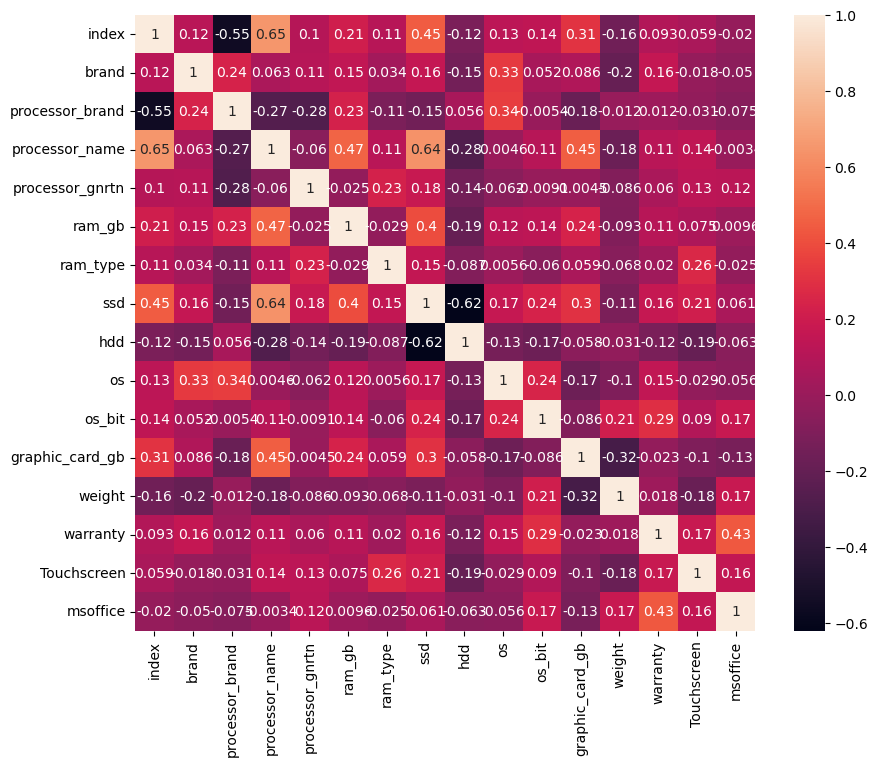

In [237]:
plt.figure(figsize=(10,8))
sns.heatmap(X_train.corr(),annot=True)

In [238]:
scaler=StandardScaler()

In [239]:
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [240]:
#A logarithmic transformation was applied to correct the right skewness in the price distribution and minimize the model's error margin at high prices.
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

## CHOOSING THE BEST MODEL WITH LAZY

In [241]:
lazy=LazyRegressor()
models,predict=lazy.fit(X_train,X_test,y_train_log,y_test_log)

In [242]:
models

,Adjusted R-Squared,R-Squared,RMSE,Time Taken
Model,,,,
GradientBoostingRegressor,0.855024,0.869254,0.160575,0.129428
BaggingRegressor,0.851852,0.866394,0.162321,0.052372
RandomForestRegressor,0.846654,0.861707,0.165144,0.448249
HistGradientBoostingRegressor,0.838808,0.854630,0.169317,0.265503
ExtraTreesRegressor,0.836363,0.852425,0.170596,0.386928
SVR,0.831575,0.848108,0.173074,0.040440
NuSVR,0.827249,0.844206,0.175282,0.057007
KNeighborsRegressor,0.803124,0.822449,0.187122,0.013166
LarsCV,0.784926,0.806038,0.195579,0.027206


In [243]:
# Showing outlier values

<Axes: xlabel='Price'>

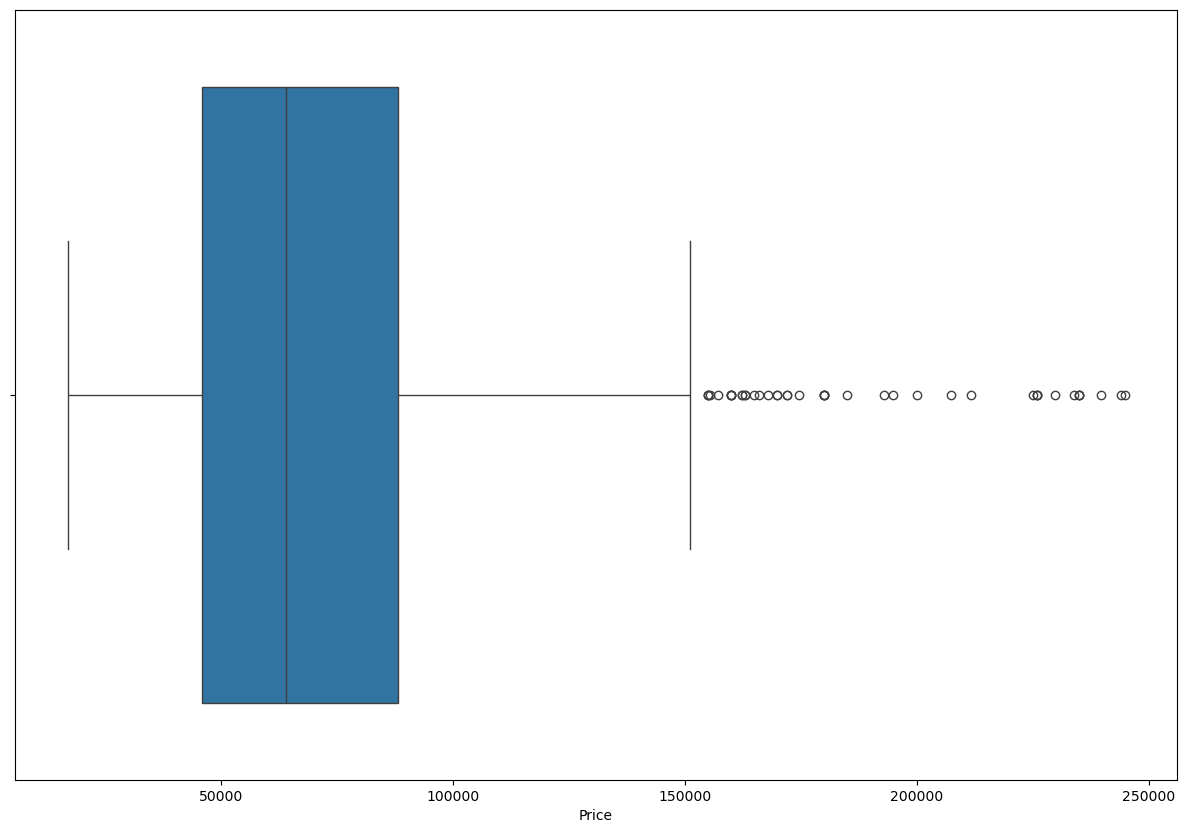

In [244]:
plt.figure(figsize=(15,10))
sns.boxplot(data=df,x="Price")

In [245]:
# we have choosed this model => GradientBoostingRegressor

In [246]:
gradient=GradientBoostingRegressor(random_state=42)

In [247]:
gradient.fit(X_train,y_train_log)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [248]:
y_pred=gradient.predict(X_test)

In [249]:
score=r2_score(y_test_log,y_pred)
mse=mean_squared_error(y_test_log,y_pred)
mae=mean_absolute_error(y_test_log,y_pred)
print(f"R-Score: {score}")
print(f"mean squared error: {mse}")
print(f"mean absolute error: {mae}")

R-Score: 0.8692543854856101
mean squared error: 0.025784181992384195
mean absolute error: 0.11615632029919026


In [250]:
# Showing guess and real values

In [251]:
y_pred_real=np.expm1(y_pred)
y_test_real=np.expm1(y_test_log)
info_df=pd.DataFrame({"Guess":y_pred_real,"Real":y_test_real,"Margin of Error":np.abs(y_pred_real-y_test_real)}).reset_index()
info_df=info_df.drop("index",axis=1)
info_df.head(10)

,Guess,Real,Margin of Error
0,147550.256520,129990.0,17560.256520
1,67694.164616,68100.0,405.835384
2,108272.293595,84990.0,23282.293595
3,68535.533665,65990.0,2545.533665
4,39182.760765,36990.0,2192.760765
5,39258.092202,34500.0,4758.092202
6,63847.251347,65990.0,2142.748653
7,85706.400231,78900.0,6806.400231
8,57339.174452,46990.0,10349.174452
9,101704.180453,109990.0,8285.819547


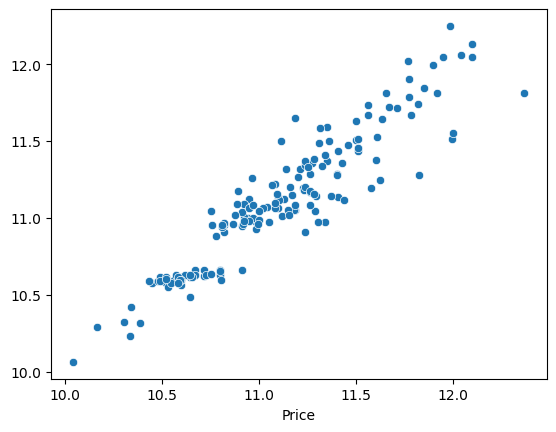

In [252]:
sns.scatterplot(x=y_test_log,y=y_pred) 
plt.show()

In [253]:
# Showing the most used features

Text(0.5, 1.0, 'Which feature has the biggest impact on the price?')

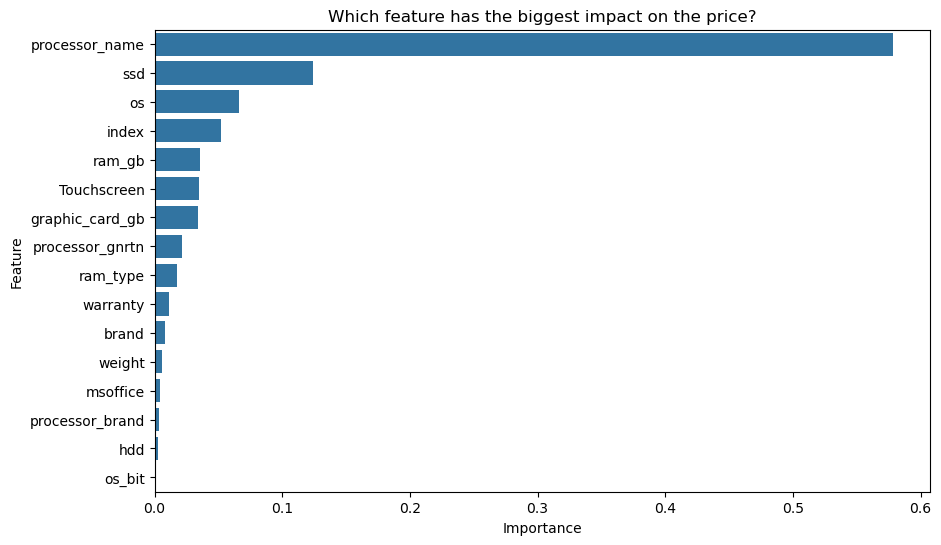

In [254]:
importances_order= gradient.feature_importances_ 
feature_names = X.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances_order}).sort_values(by='Importance', ascending=False)
plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
plt.title('Which feature has the biggest impact on the price?')

In [256]:
joblib.dump(gradient, 'laptop_model.pkl') 

['laptop_model.pkl']